In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("../Data/raw/retail_store_sales.csv")

In [3]:
print("Dataset Shape:", df.shape)

Dataset Shape: (12575, 11)


In [4]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [5]:
df.tail()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
12570,TXN_9347481,CUST_18,Patisserie,Item_23_PAT,38.0,4.0,152.0,Credit Card,In-store,2023-09-03,NaN
12571,TXN_4009414,CUST_03,Beverages,Item_2_BEV,6.5,9.0,58.5,Cash,Online,2022-08-12,False
12572,TXN_5306010,CUST_11,Butchers,Item_7_BUT,14.0,10.0,140.0,Cash,Online,2024-08-24,NaN
12573,TXN_5167298,CUST_04,Furniture,Item_7_FUR,14.0,6.0,84.0,Cash,Online,2023-12-30,True
12574,TXN_2407494,CUST_23,Food,Item_9_FOOD,17.0,3.0,51.0,Cash,Online,2022-08-06,NaN


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  str    
 1   Customer ID       12575 non-null  str    
 2   Category          12575 non-null  str    
 3   Item              11362 non-null  str    
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  str    
 8   Location          12575 non-null  str    
 9   Transaction Date  12575 non-null  str    
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(1), str(7)
memory usage: 1.1+ MB


In [7]:
print(df.columns)

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='str')


In [8]:
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

Missing Values in Each Column:
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199
dtype: int64


In [9]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("Missing Value Percentage:")
print(missing_percentage.round(2))

Missing Value Percentage:
Transaction ID       0.00
Customer ID          0.00
Category             0.00
Item                 9.65
Price Per Unit       4.84
Quantity             4.80
Total Spent          4.80
Payment Method       0.00
Location             0.00
Transaction Date     0.00
Discount Applied    33.39
dtype: float64


In [10]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [11]:
print("Column Data Types:")
print(df.dtypes)

Column Data Types:
Transaction ID          str
Customer ID             str
Category                str
Item                    str
Price Per Unit      float64
Quantity            float64
Total Spent         float64
Payment Method          str
Location                str
Transaction Date        str
Discount Applied     object
dtype: object


In [12]:
df.describe()

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


In [13]:
print("Unique Categories:")
print(df["Category"].unique())

print("\nUnique Payment Methods:")
print(df["Payment Method"].unique())

print("\nUnique Locations:")
print(df["Location"].unique())

Unique Categories:
<StringArray>
[                        'Patisserie',                      'Milk Products',
                           'Butchers',                          'Beverages',
                               'Food',                          'Furniture',
      'Electric household essentials', 'Computers and electric accessories']
Length: 8, dtype: str

Unique Payment Methods:
<StringArray>
['Digital Wallet', 'Credit Card', 'Cash']
Length: 3, dtype: str

Unique Locations:
<StringArray>
['Online', 'In-store']
Length: 2, dtype: str


In [14]:
cleaned_df = df.copy()

print("Original Dataset Shape:", df.shape)
print("Working Dataset Shape:", cleaned_df.shape)

Original Dataset Shape: (12575, 11)
Working Dataset Shape: (12575, 11)


In [15]:
print(cleaned_df["Discount Applied"].value_counts(dropna=False))

Discount Applied
True     4219
NaN      4199
False    4157
Name: count, dtype: int64


In [16]:
print("Unique Discount Values:")
print(cleaned_df["Discount Applied"].unique())

Unique Discount Values:
[True False nan]


In [17]:
print("Missing Item Records:")
print(cleaned_df[cleaned_df["Item"].isnull()].head(10))

Missing Item Records:
   Transaction ID Customer ID       Category Item  Price Per Unit  Quantity  \
5     TXN_7482416     CUST_09     Patisserie  NaN             NaN      10.0   
7     TXN_1372952     CUST_21      Furniture  NaN            33.5       NaN   
11    TXN_5422631     CUST_09  Milk Products  NaN             NaN       8.0   
15    TXN_1809665     CUST_14      Beverages  NaN            24.5       NaN   
17    TXN_9634894     CUST_15  Milk Products  NaN             NaN      10.0   
19    TXN_4206593     CUST_01      Furniture  NaN            35.0       NaN   
21    TXN_8685338     CUST_15  Milk Products  NaN             NaN       3.0   
25    TXN_3481599     CUST_05      Furniture  NaN            39.5       NaN   
32    TXN_1543244     CUST_20           Food  NaN             NaN       8.0   
34    TXN_1621497     CUST_06     Patisserie  NaN            23.0       NaN   

    Total Spent  Payment Method  Location Transaction Date Discount Applied  
5         200.0     Credit Car

In [18]:
cleaned_df["Transaction Date"] = pd.to_datetime(
    cleaned_df["Transaction Date"],
    errors="coerce"
)

print(cleaned_df["Transaction Date"].dtype)

datetime64[us]


In [19]:
print(cleaned_df[[
    "Price Per Unit",
    "Quantity",
    "Total Spent"
]].isnull().sum())

Price Per Unit    609
Quantity          604
Total Spent       604
dtype: int64


In [20]:
print("Missing Value Combinations:")

print(
    cleaned_df[
        ["Price Per Unit", "Quantity", "Total Spent"]
    ].isnull().value_counts()
)

Missing Value Combinations:
Price Per Unit  Quantity  Total Spent
False           False     False          11362
True            False     False            609
False           True      True             604
Name: count, dtype: int64


In [21]:
print(
    cleaned_df[
        cleaned_df["Total Spent"].isnull()
    ][["Price Per Unit", "Quantity", "Total Spent"]].head(10)
)

     Price Per Unit  Quantity  Total Spent
7              33.5       NaN          NaN
15             24.5       NaN          NaN
19             35.0       NaN          NaN
25             39.5       NaN          NaN
34             23.0       NaN          NaN
83             15.5       NaN          NaN
112            20.0       NaN          NaN
114            39.5       NaN          NaN
118            27.5       NaN          NaN
138            35.0       NaN          NaN


In [22]:
print(
    cleaned_df[
        cleaned_df["Price Per Unit"].isnull()
    ][["Price Per Unit", "Quantity", "Total Spent"]].head(10)
)

     Price Per Unit  Quantity  Total Spent
5               NaN      10.0        200.0
11              NaN       8.0         52.0
17              NaN      10.0        275.0
21              NaN       3.0        105.0
32              NaN       8.0        196.0
127             NaN      10.0        275.0
159             NaN       9.0        126.0
216             NaN       8.0         40.0
247             NaN       7.0        150.5
271             NaN       9.0         99.0


In [23]:
cleaned_df["Item"] = cleaned_df["Item"].fillna("Unknown")

In [24]:
cleaned_df["Discount Applied"] = (
    cleaned_df["Discount Applied"].astype("object").fillna("Unknown")
)

print(cleaned_df["Discount Applied"].value_counts())

Discount Applied
True       4219
Unknown    4199
False      4157
Name: count, dtype: int64


In [25]:
print("Missing Values After Initial Cleaning:")
print(cleaned_df.isnull().sum())

Missing Values After Initial Cleaning:
Transaction ID        0
Customer ID           0
Category              0
Item                  0
Price Per Unit      609
Quantity            604
Total Spent         604
Payment Method        0
Location              0
Transaction Date      0
Discount Applied      0
dtype: int64


In [26]:
cleaned_df = cleaned_df.dropna(
    subset=["Price Per Unit", "Quantity", "Total Spent"]
)

print("Shape After Removing Missing Numerical Values:")
print(cleaned_df.shape)

print("\nMissing Values:")
print(cleaned_df.isnull().sum())

Shape After Removing Missing Numerical Values:
(11362, 11)

Missing Values:
Transaction ID      0
Customer ID         0
Category            0
Item                0
Price Per Unit      0
Quantity            0
Total Spent         0
Payment Method      0
Location            0
Transaction Date    0
Discount Applied    0
dtype: int64


In [27]:
print("Duplicate Rows:", cleaned_df.duplicated().sum())

Duplicate Rows: 0


In [28]:
print(cleaned_df.dtypes)

Transaction ID                 str
Customer ID                    str
Category                       str
Item                           str
Price Per Unit             float64
Quantity                   float64
Total Spent                float64
Payment Method                 str
Location                       str
Transaction Date    datetime64[us]
Discount Applied            object
dtype: object


In [6]:
cleaned_df.to_csv(
    "../Data/cleaned/cleaned_retail_store_sales.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [5]:
cleaned_df = pd.read_csv(
    "../Data/cleaned/cleaned_retail_store_sales.csv"
)

cleaned_df["Transaction Date"] = pd.to_datetime(
    cleaned_df["Transaction Date"]
)

print("Cleaned Dataset Loaded Successfully!")
print("Dataset Shape:", cleaned_df.shape)

cleaned_df.head()

Cleaned Dataset Loaded Successfully!
Dataset Shape: (11362, 11)


,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,Unknown
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


In [32]:
print("Total Sales:", cleaned_df["Total Spent"].sum())

print("Average Sales:", cleaned_df["Total Spent"].mean())

print("Maximum Sales:", cleaned_df["Total Spent"].max())

print("Minimum Sales:", cleaned_df["Total Spent"].min())

print("Total Transactions:", cleaned_df["Transaction ID"].nunique())

print("Total Customers:", cleaned_df["Customer ID"].nunique())

Total Sales: 1472998.5
Average Sales: 129.64253652525963
Maximum Sales: 410.0
Minimum Sales: 5.0
Total Transactions: 11362
Total Customers: 25


In [33]:
category_sales = cleaned_df.groupby("Category")["Total Spent"].sum()

category_sales = category_sales.sort_values(ascending=False)

print("Sales by Category:")
print(category_sales)

Sales by Category:
Category
Butchers                              197426.0
Electric household essentials         192441.5
Beverages                             187978.5
Furniture                             186527.0
Food                                  184645.0
Computers and electric accessories    180902.5
Patisserie                            172330.5
Milk Products                         170747.5
Name: Total Spent, dtype: float64


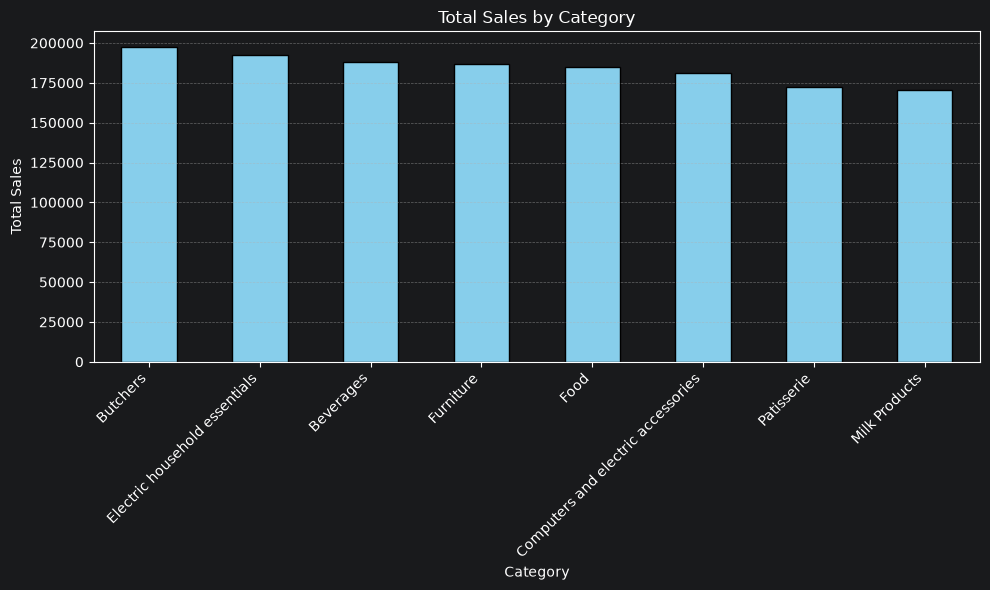

In [34]:
plt.figure(figsize=(10, 6))

category_sales.plot(kind="bar", color="skyblue", edgecolor="black")

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [35]:
payment_sales = cleaned_df.groupby("Payment Method")["Total Spent"].sum()

payment_sales = payment_sales.sort_values(ascending=False)

print("Sales by Payment Method:")
print(payment_sales)

Sales by Payment Method:
Payment Method
Cash              513676.0
Credit Card       481135.0
Digital Wallet    478187.5
Name: Total Spent, dtype: float64


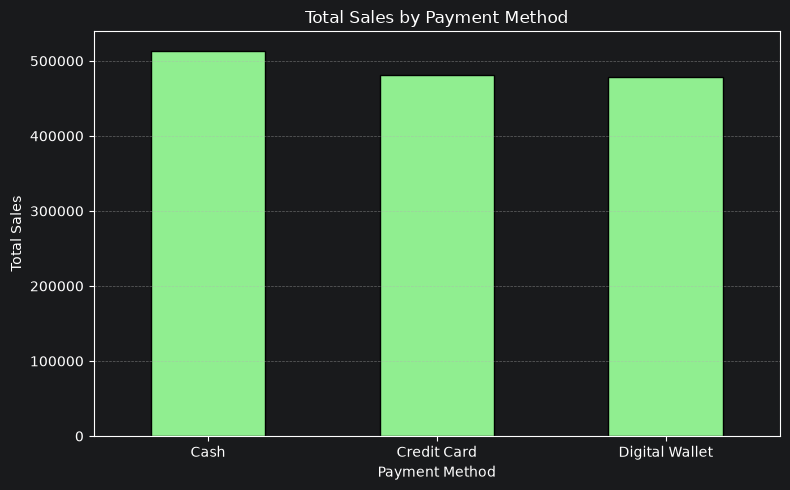

In [36]:
plt.figure(figsize=(8, 5))

payment_sales.plot(
    kind="bar",
    color="lightgreen",
    edgecolor="black"
)

plt.title("Total Sales by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [37]:
location_sales = cleaned_df.groupby("Location")["Total Spent"].sum()

location_sales = location_sales.sort_values(ascending=False)

print("Sales by Location:")
print(location_sales)

Sales by Location:
Location
Online      749431.0
In-store    723567.5
Name: Total Spent, dtype: float64


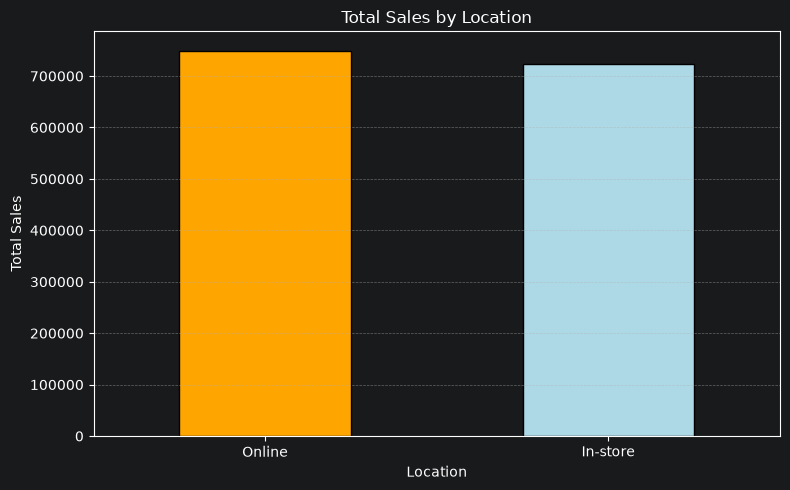

In [38]:
plt.figure(figsize=(8, 5))

location_sales.plot(
    kind="bar",
    color=["orange", "lightblue"],
    edgecolor="black"
)

plt.title("Total Sales by Location")
plt.xlabel("Location")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [39]:
top_items = cleaned_df.groupby("Item")["Quantity"].sum()

top_items = top_items.sort_values(ascending=False).head(10)

print("Top 10 Best-Selling Items:")
print(top_items)

Top 10 Best-Selling Items:
Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64


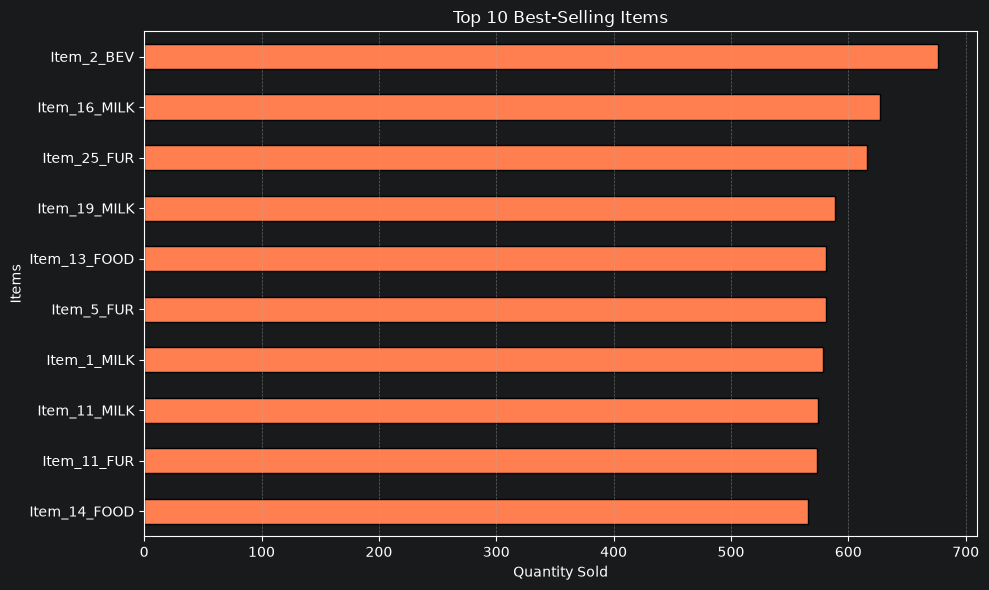

In [40]:
plt.figure(figsize=(10, 6))

top_items.sort_values().plot(
    kind="barh",
    color="coral",
    edgecolor="black"
)

plt.title("Top 10 Best-Selling Items")
plt.xlabel("Quantity Sold")
plt.ylabel("Items")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [41]:
cleaned_df["Month"] = cleaned_df["Transaction Date"].dt.to_period("M")

monthly_sales = cleaned_df.groupby("Month")["Total Spent"].sum()

print("Monthly Sales:")
print(monthly_sales)

Monthly Sales:
Month
2022-01    50525.0
2022-02    41579.5
2022-03    38566.0
2022-04    38650.0
2022-05    38752.5
2022-06    40846.0
2022-07    41098.5
2022-08    38178.0
2022-09    44287.0
2022-10    35580.5
2022-11    39989.0
2022-12    36249.5
2023-01    45989.5
2023-02    36520.0
2023-03    35978.5
2023-04    37003.0
2023-05    38563.0
2023-06    40540.0
2023-07    43334.0
2023-08    37238.5
2023-09    37945.5
2023-10    36091.5
2023-11    34900.0
2023-12    41046.0
2024-01    44885.0
2024-02    35054.0
2024-03    40841.5
2024-04    43280.5
2024-05    42254.0
2024-06    42583.0
2024-07    39896.0
2024-08    41459.0
2024-09    40023.5
2024-10    41399.5
2024-11    41367.5
2024-12    46292.5
2025-01    24211.5
Freq: M, Name: Total Spent, dtype: float64


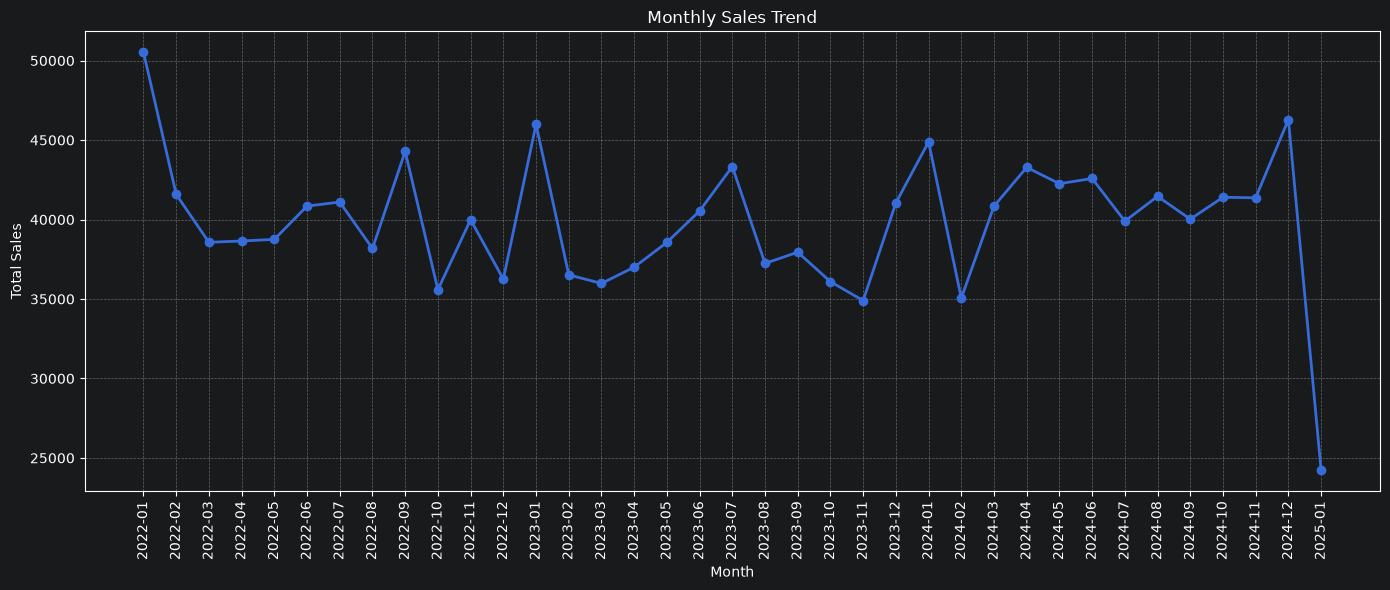

In [42]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o",
    linestyle="-",
    linewidth=2
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=90)
plt.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [43]:
discount_sales = cleaned_df.groupby("Discount Applied")["Total Spent"].sum()

print("Sales by Discount Status:")
print(discount_sales)

Sales by Discount Status:
Discount Applied
False      491632.5
True       496880.5
Unknown    484485.5
Name: Total Spent, dtype: float64


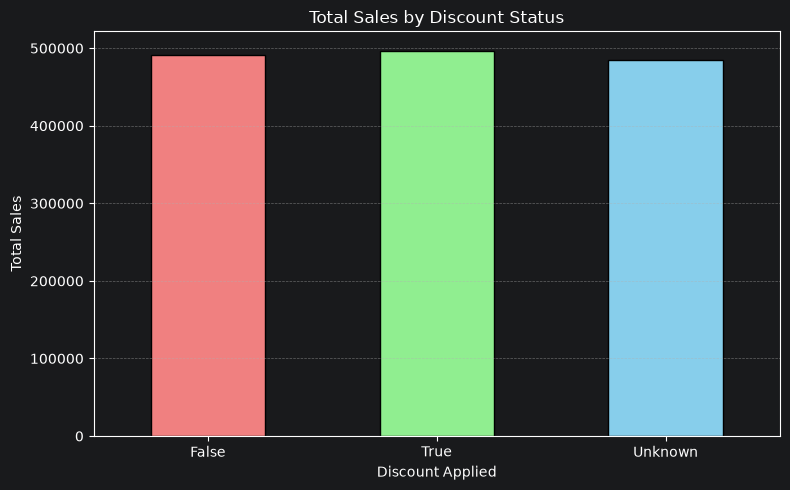

In [44]:
plt.figure(figsize=(8, 5))

discount_sales.plot(
    kind="bar",
    color=["lightcoral", "lightgreen", "skyblue"],
    edgecolor="black"
)

plt.title("Total Sales by Discount Status")
plt.xlabel("Discount Applied")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [45]:
customer_sales = cleaned_df.groupby("Customer ID")["Total Spent"].sum()

top_customers = customer_sales.sort_values(
    ascending=False
).head(10)

print("Top 10 Customers by Spending:")
print(top_customers)

Top 10 Customers by Spending:
Customer ID
CUST_24    64608.0
CUST_05    63855.5
CUST_16    63185.5
CUST_13    63015.5
CUST_08    62850.5
CUST_15    60749.5
CUST_10    60367.5
CUST_23    59738.5
CUST_21    59639.0
CUST_02    59512.5
Name: Total Spent, dtype: float64


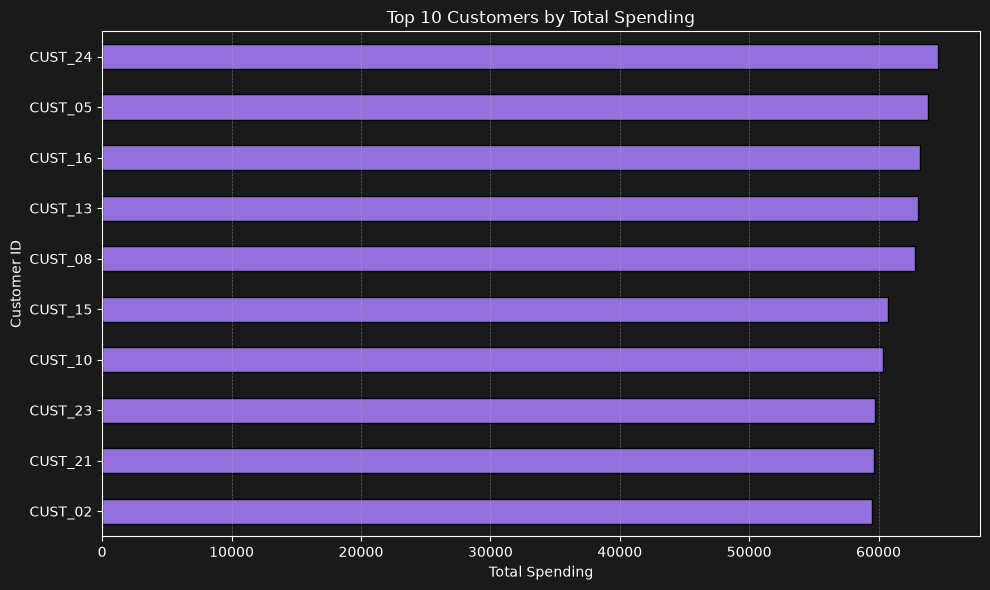

In [46]:
plt.figure(figsize=(10, 6))

top_customers.sort_values().plot(
    kind="barh",
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Top 10 Customers by Total Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [47]:
category_transactions = cleaned_df["Category"].value_counts()

print("Transactions by Category:")
print(category_transactions)

Transactions by Category:
Category
Furniture                             1460
Electric household essentials         1437
Beverages                             1427
Food                                  1426
Milk Products                         1425
Butchers                              1421
Computers and electric accessories    1397
Patisserie                            1369
Name: count, dtype: int64


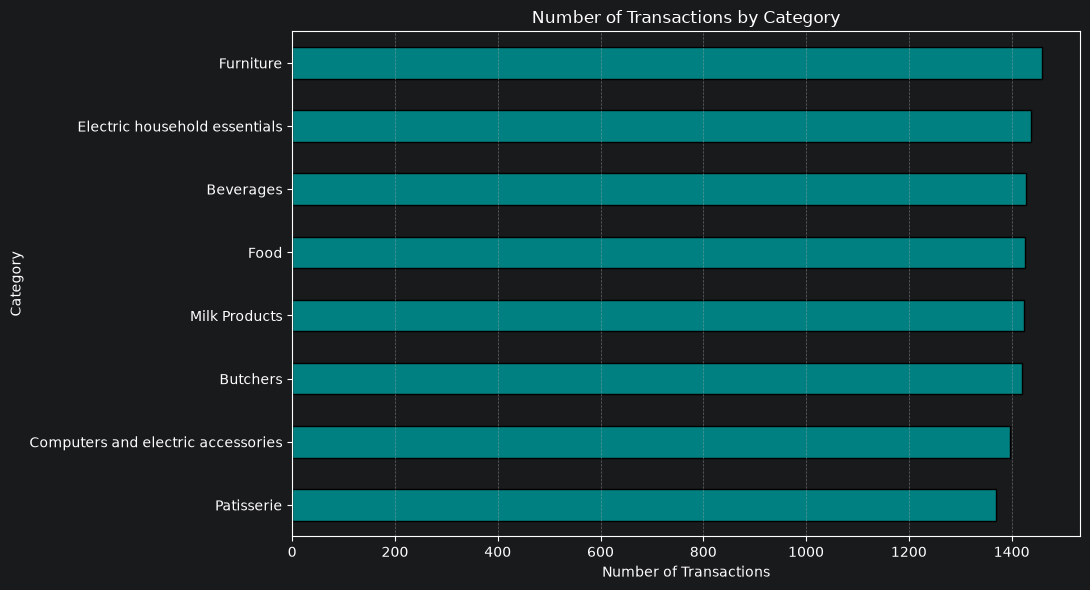

In [48]:
plt.figure(figsize=(11, 6))

category_transactions.sort_values().plot(
    kind="barh",
    color="teal",
    edgecolor="black"
)

plt.title("Number of Transactions by Category")
plt.xlabel("Number of Transactions")
plt.ylabel("Category")
plt.grid(axis="x", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [49]:
average_payment_sales = cleaned_df.groupby("Payment Method")["Total Spent"].mean()

average_payment_sales = average_payment_sales.sort_values(ascending=False)

print("Average Spending by Payment Method:")
print(average_payment_sales)

Average Spending by Payment Method:
Payment Method
Cash              131.140158
Credit Card       129.025208
Digital Wallet    128.683396
Name: Total Spent, dtype: float64


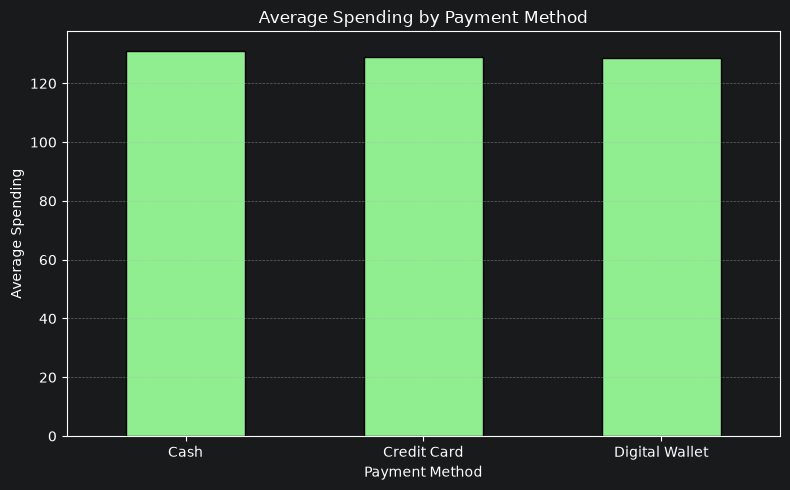

In [50]:
plt.figure(figsize=(8, 5))

average_payment_sales.plot(
    kind="bar",
    color="lightgreen",
    edgecolor="black"
)

plt.title("Average Spending by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Average Spending")

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [51]:
category_payment_sales = cleaned_df.pivot_table(
    index="Category",
    columns="Payment Method",
    values="Total Spent",
    aggfunc="sum"
)

print("Sales by Category and Payment Method:")
print(category_payment_sales)

Sales by Category and Payment Method:
Payment Method                         Cash  Credit Card  Digital Wallet
Category                                                                
Beverages                           67380.0      58611.0         61987.5
Butchers                            68499.0      69793.0         59134.0
Computers and electric accessories  64621.0      59394.5         56887.0
Electric household essentials       64877.5      57997.5         69566.5
Food                                65811.5      59896.5         58937.0
Furniture                           64830.5      61590.0         60106.5
Milk Products                       58528.0      57155.5         55064.0
Patisserie                          59128.5      56697.0         56505.0


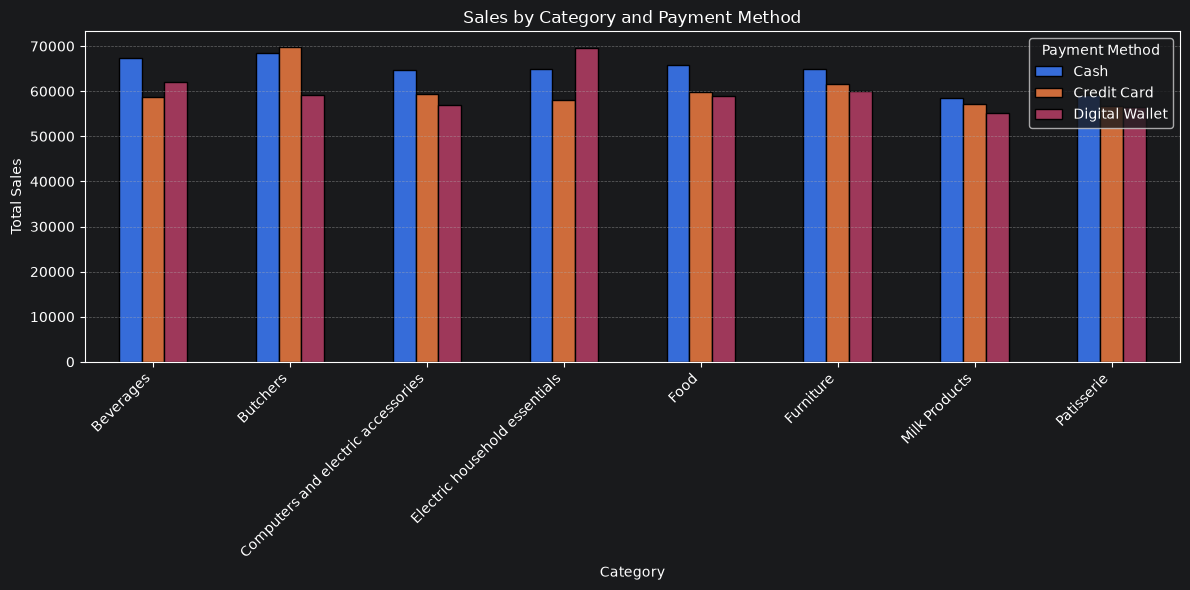

In [52]:
category_payment_sales.plot(
    kind="bar",
    figsize=(12, 6),
    edgecolor="black"
)

plt.title("Sales by Category and Payment Method")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Payment Method")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [53]:
average_category_sales = cleaned_df.groupby("Category")["Total Spent"].mean()

average_category_sales = average_category_sales.sort_values(
    ascending=False
)

print("Average Sales by Category:")
print(average_category_sales)

Average Sales by Category:
Category
Butchers                              138.934553
Electric household essentials         133.918928
Beverages                             131.729853
Computers and electric accessories    129.493558
Food                                  129.484572
Furniture                             127.758219
Patisserie                            125.880570
Milk Products                         119.822807
Name: Total Spent, dtype: float64


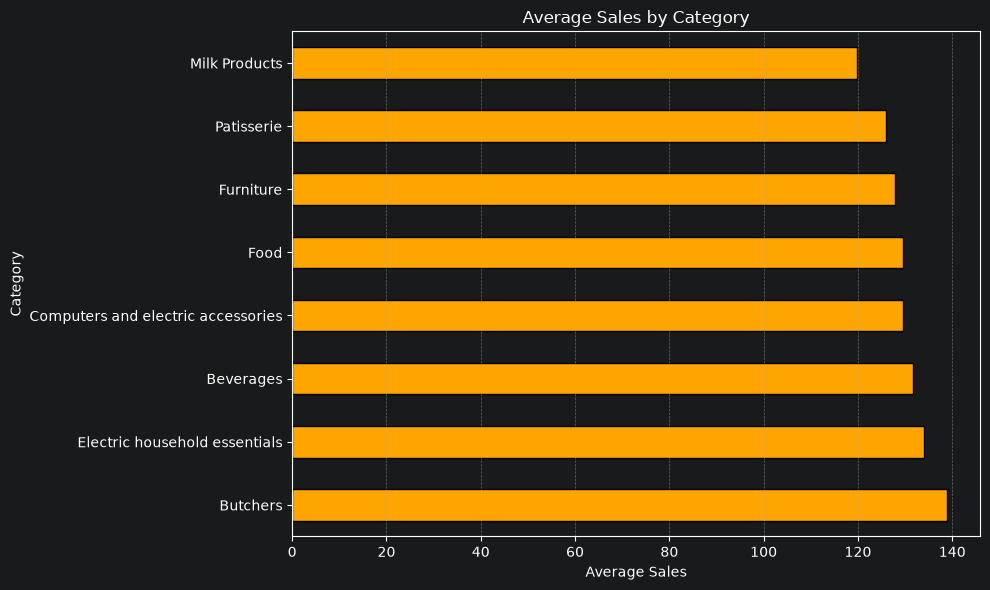

In [54]:
plt.figure(figsize=(10, 6))

average_category_sales.plot(
    kind="barh",
    color="orange",
    edgecolor="black"
)

plt.title("Average Sales by Category")
plt.xlabel("Average Sales")
plt.ylabel("Category")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [55]:
daily_sales = cleaned_df.groupby(
    cleaned_df["Transaction Date"].dt.date
)["Total Spent"].sum()

print("Daily Sales:")
print(daily_sales.head(10))

Daily Sales:
Transaction Date
2022-01-01    1642.5
2022-01-02    1135.5
2022-01-03     823.0
2022-01-04    1082.5
2022-01-05    2227.5
2022-01-06     728.5
2022-01-07    1372.5
2022-01-08    1463.0
2022-01-09    1866.0
2022-01-10    1266.5
Name: Total Spent, dtype: float64


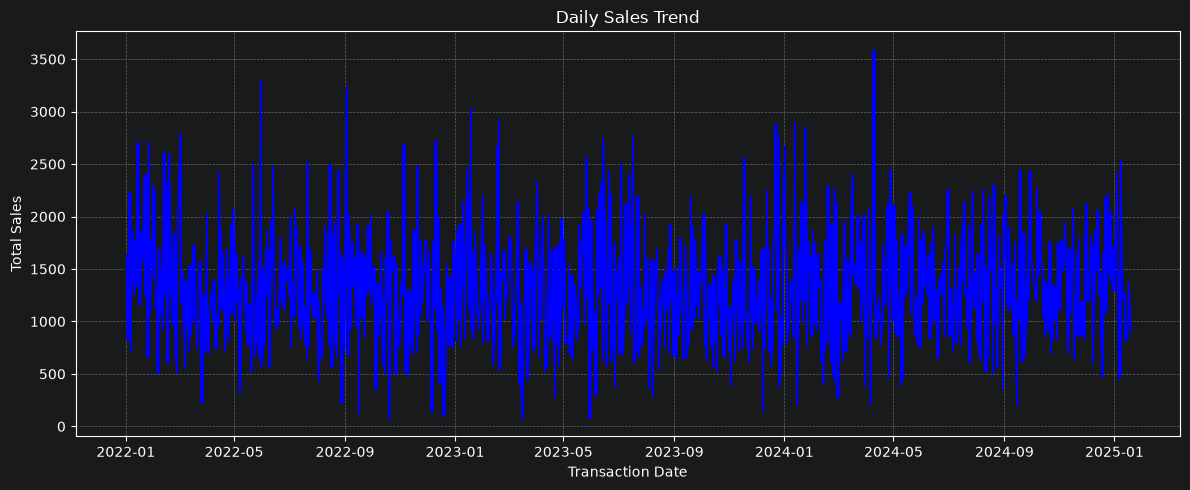

In [56]:
plt.figure(figsize=(12, 5))

daily_sales.plot(
    kind="line",
    color="blue"
)

plt.title("Daily Sales Trend")
plt.xlabel("Transaction Date")
plt.ylabel("Total Sales")

plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [57]:
highest_sales_day = daily_sales.idxmax()
highest_sales = daily_sales.max()

lowest_sales_day = daily_sales.idxmin()
lowest_sales = daily_sales.min()

print("Highest Sales Day:")
print(highest_sales_day, "-", highest_sales)

print("\nLowest Sales Day:")
print(lowest_sales_day, "-", lowest_sales)

Highest Sales Day:
2024-04-09 - 3589.5

Lowest Sales Day:
2023-05-30 - 79.0


In [58]:
cleaned_df["Year"] = cleaned_df["Transaction Date"].dt.year

yearly_sales = cleaned_df.groupby("Year")["Total Spent"].sum()

print("Yearly Sales:")
print(yearly_sales)


Yearly Sales:
Year
2022    484301.5
2023    465149.5
2024    499336.0
2025     24211.5
Name: Total Spent, dtype: float64


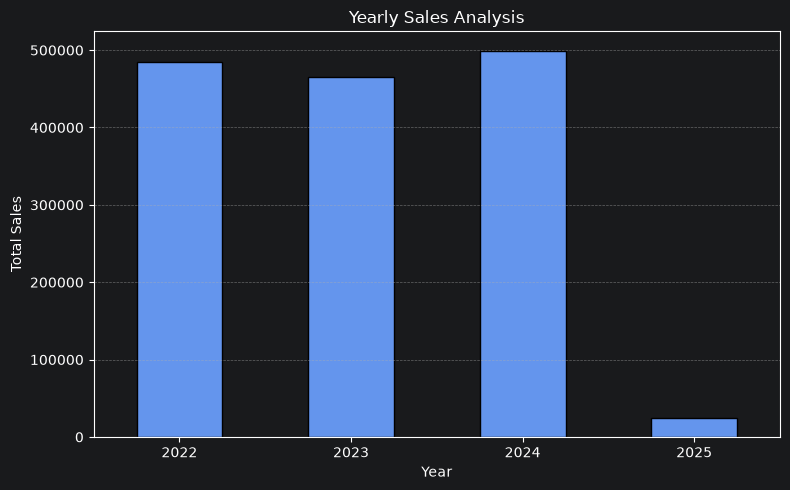

In [59]:
plt.figure(figsize=(8, 5))

yearly_sales.plot(
    kind="bar",
    color="cornflowerblue",
    edgecolor="black"
)

plt.title("Yearly Sales Analysis")
plt.xlabel("Year")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [60]:
cleaned_df["Month Name"] = cleaned_df["Transaction Date"].dt.month_name()

monthly_name_sales = cleaned_df.groupby("Month Name")["Total Spent"].sum()

month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_name_sales = monthly_name_sales.reindex(month_order)

print("Sales by Month Name:")
print(monthly_name_sales)

Sales by Month Name:
Month Name
January      165611.0
February     113153.5
March        115386.0
April        118933.5
May          119569.5
June         123969.0
July         124328.5
August       116875.5
September    122256.0
October      113071.5
November     116256.5
December     123588.0
Name: Total Spent, dtype: float64


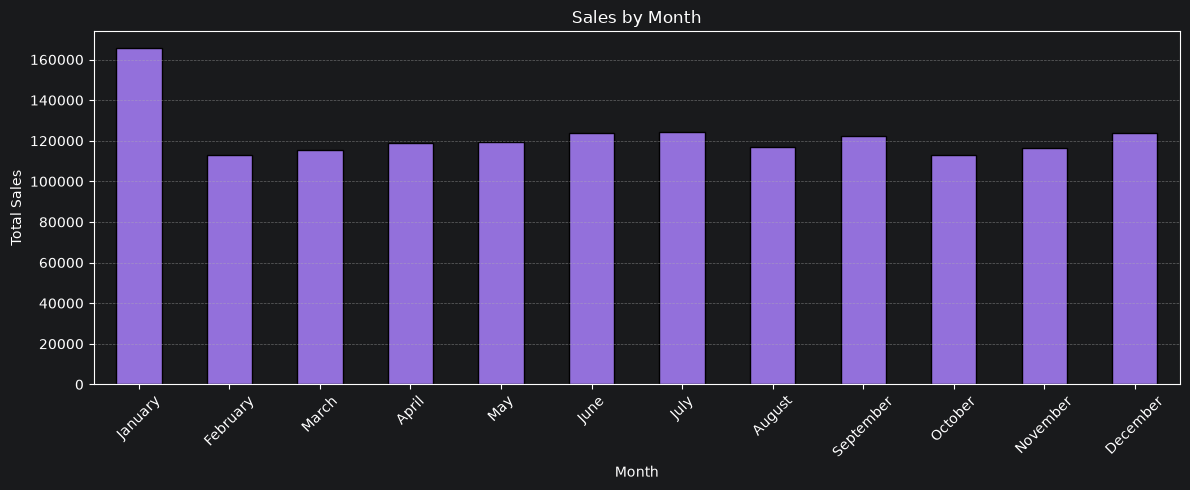

In [61]:
plt.figure(figsize=(12, 5))

monthly_name_sales.plot(
    kind="bar",
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Sales by Month")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [62]:
category_quantity = cleaned_df.groupby("Category")["Quantity"].sum()

category_quantity = category_quantity.sort_values(
    ascending=False
)

print("Total Quantity Sold by Category:")
print(category_quantity)

Total Quantity Sold by Category:
Category
Furniture                             8083.0
Beverages                             7974.0
Food                                  7925.0
Electric household essentials         7897.0
Milk Products                         7889.0
Computers and electric accessories    7832.0
Butchers                              7774.0
Patisserie                            7515.0
Name: Quantity, dtype: float64


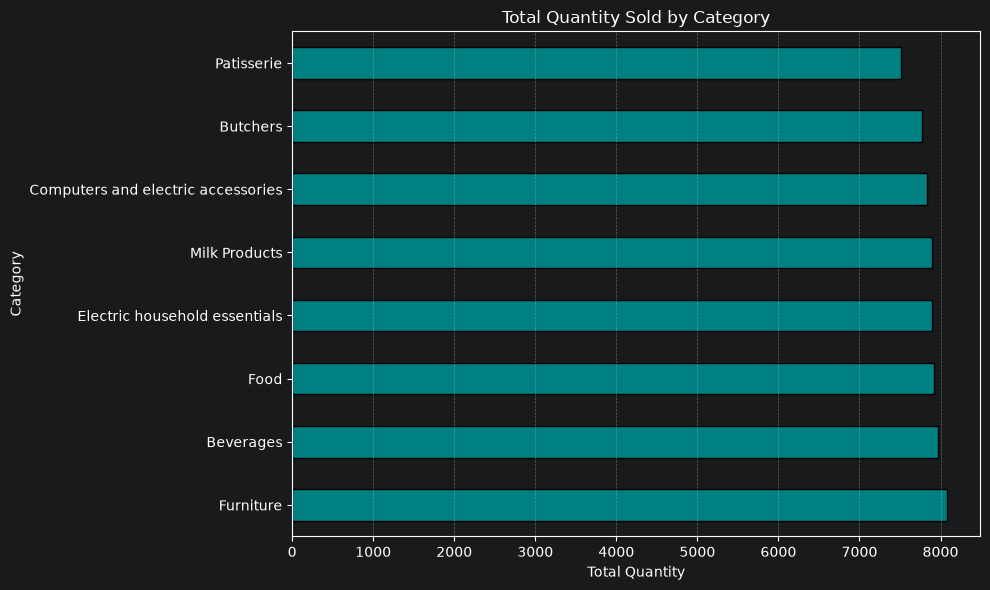

In [63]:
plt.figure(figsize=(10, 6))

category_quantity.plot(
    kind="barh",
    color="teal",
    edgecolor="black"
)

plt.title("Total Quantity Sold by Category")
plt.xlabel("Total Quantity")
plt.ylabel("Category")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [64]:
average_quantity = cleaned_df.groupby("Category")["Quantity"].mean()

average_quantity = average_quantity.sort_values(
    ascending=False
)

print("Average Quantity by Category:")
print(average_quantity)

Average Quantity by Category:
Category
Computers and electric accessories    5.606299
Beverages                             5.587947
Food                                  5.557504
Furniture                             5.536301
Milk Products                         5.536140
Electric household essentials         5.495477
Patisserie                            5.489408
Butchers                              5.470795
Name: Quantity, dtype: float64


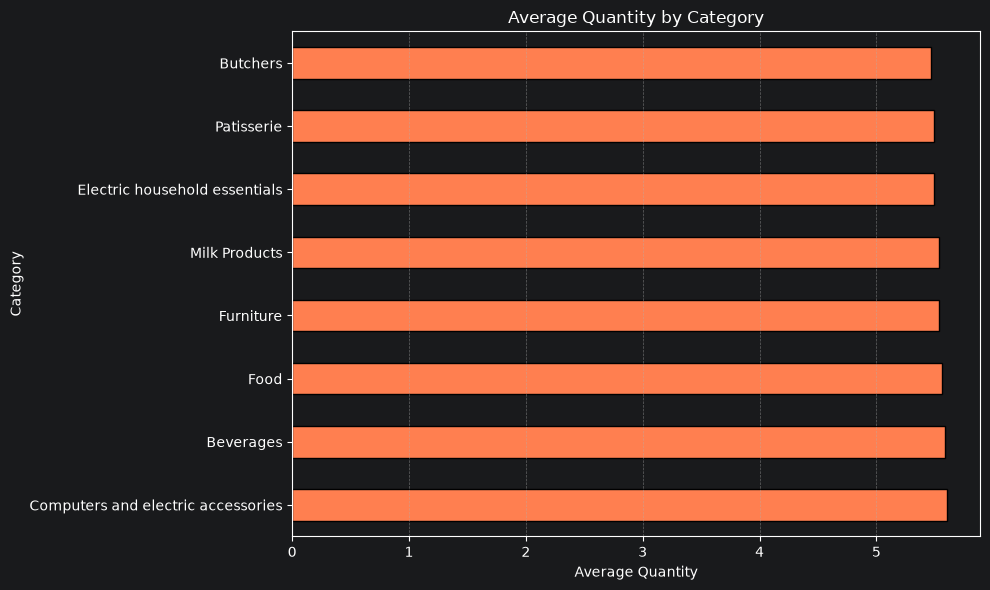

In [65]:
plt.figure(figsize=(10, 6))

average_quantity.plot(
    kind="barh",
    color="coral",
    edgecolor="black"
)

plt.title("Average Quantity by Category")
plt.xlabel("Average Quantity")
plt.ylabel("Category")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [66]:
cleaned_df["Day"] = cleaned_df["Transaction Date"].dt.day_name()

day_sales = cleaned_df.groupby("Day")["Total Spent"].sum()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_sales = day_sales.reindex(day_order)

print("Sales by Day of the Week:")
print(day_sales)

Sales by Day of the Week:
Day
Monday       201226.0
Tuesday      206833.0
Wednesday    206771.0
Thursday     208317.0
Friday       221282.5
Saturday     214464.0
Sunday       214105.0
Name: Total Spent, dtype: float64


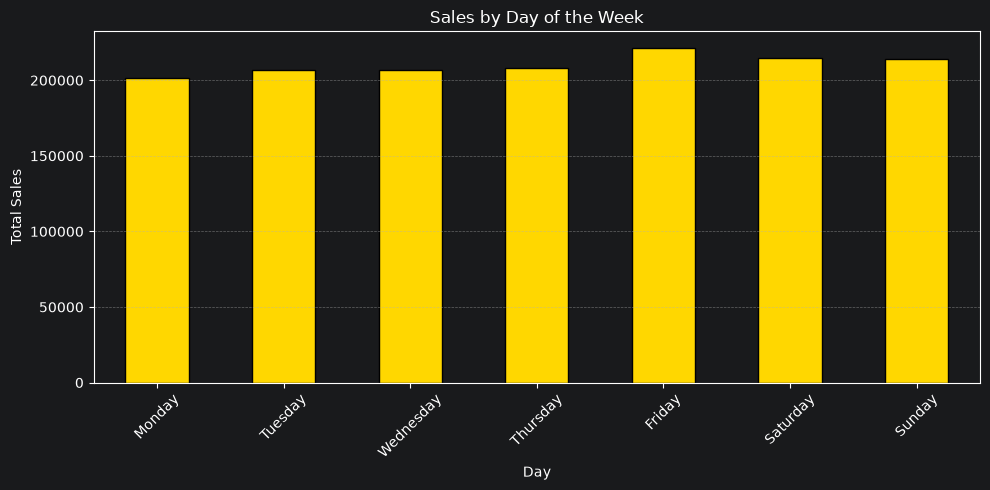

In [67]:
plt.figure(figsize=(10, 5))

day_sales.plot(
    kind="bar",
    color="gold",
    edgecolor="black"
)

plt.title("Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [68]:
average_day_sales = cleaned_df.groupby("Day")["Total Spent"].mean()

average_day_sales = average_day_sales.reindex(day_order)

print("Average Sales by Day:")
print(average_day_sales)

Average Sales by Day:
Day
Monday       126.081454
Tuesday      129.028696
Wednesday    126.620331
Thursday     129.630989
Friday       134.518237
Saturday     131.170642
Sunday       130.313451
Name: Total Spent, dtype: float64


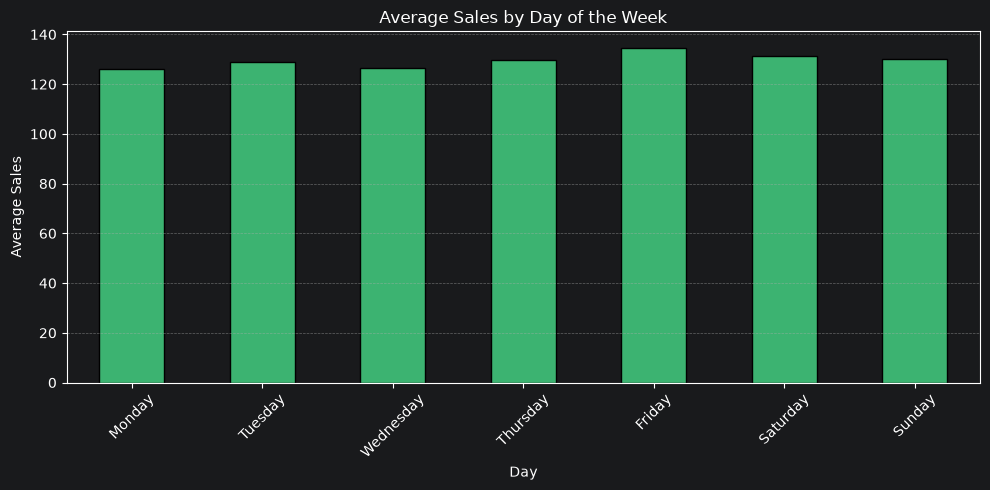

In [69]:
plt.figure(figsize=(10, 5))

average_day_sales.plot(
    kind="bar",
    color="mediumseagreen",
    edgecolor="black"
)

plt.title("Average Sales by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Average Sales")

plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [70]:
payment_location_sales = cleaned_df.pivot_table(
    index="Location",
    columns="Payment Method",
    values="Total Spent",
    aggfunc="sum"
)

print("Sales by Payment Method and Location:")
print(payment_location_sales)

Sales by Payment Method and Location:
Payment Method      Cash  Credit Card  Digital Wallet
Location                                             
In-store        251669.0     234566.5        237332.0
Online          262007.0     246568.5        240855.5


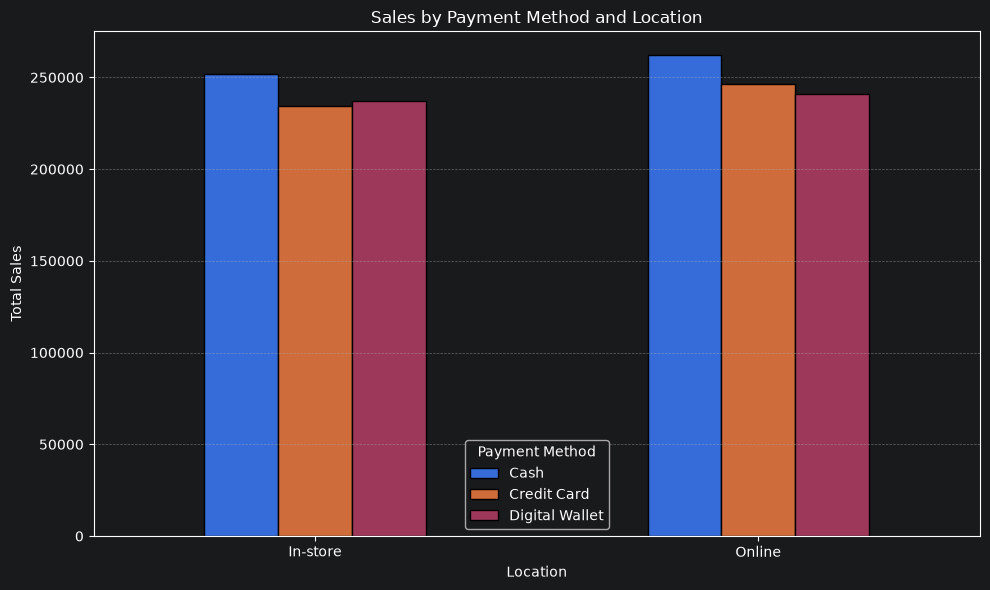

In [71]:
payment_location_sales.plot(
    kind="bar",
    figsize=(10, 6),
    edgecolor="black"
)

plt.title("Sales by Payment Method and Location")
plt.xlabel("Location")
plt.ylabel("Total Sales")

plt.xticks(rotation=0)
plt.legend(title="Payment Method")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [72]:
average_location_sales = cleaned_df.groupby("Location")["Total Spent"].mean()

print("Average Sales by Location:")
print(average_location_sales)

Average Sales by Location:
Location
In-store    128.817429
Online      130.449260
Name: Total Spent, dtype: float64


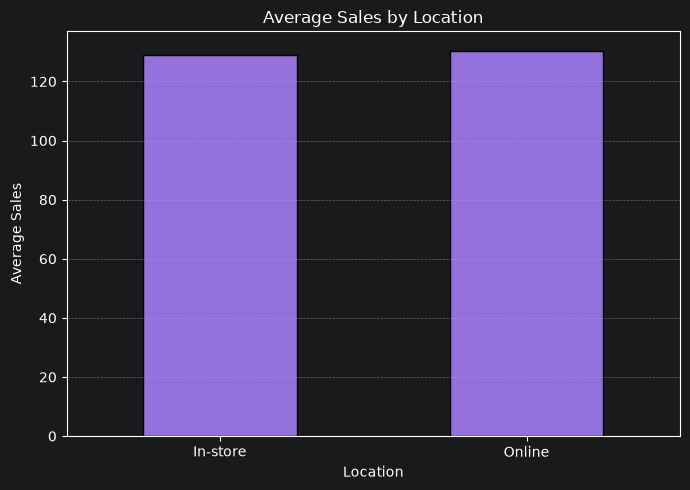

In [73]:
plt.figure(figsize=(7, 5))

average_location_sales.plot(
    kind="bar",
    color="mediumpurple",
    edgecolor="black"
)

plt.title("Average Sales by Location")
plt.xlabel("Location")
plt.ylabel("Average Sales")

plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [74]:
item_sales = cleaned_df.groupby("Item")["Total Spent"].sum()

top_10_items_sales = item_sales.sort_values(
    ascending=False
).head(10)

print("Top 10 Items by Revenue:")
print(top_10_items_sales)

Top 10 Items by Revenue:
Item
Item_25_FUR     25256.0
Item_25_EHE     23083.0
Item_25_BUT     21894.0
Item_24_FUR     21172.0
Item_25_FOOD    20541.0
Item_22_BUT     19710.0
Item_23_BUT     19114.0
Item_20_BUT     18860.5
Item_19_MILK    18848.0
Item_23_EHE     18468.0
Name: Total Spent, dtype: float64


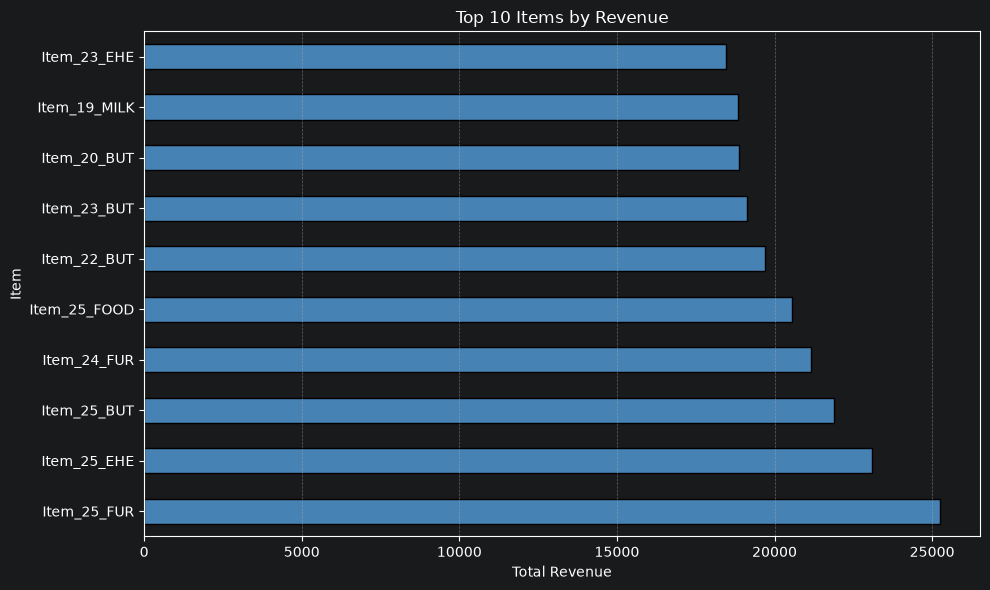

In [75]:
plt.figure(figsize=(10, 6))

top_10_items_sales.plot(
    kind="barh",
    color="steelblue",
    edgecolor="black"
)

plt.title("Top 10 Items by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Item")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [76]:
customer_transactions = cleaned_df.groupby("Customer ID")["Transaction ID"].nunique()

top_10_customers_transactions = customer_transactions.sort_values(
    ascending=False
).head(10)

print("Top 10 Customers by Transactions:")
print(top_10_customers_transactions)

Top 10 Customers by Transactions:
Customer ID
CUST_05    497
CUST_13    491
CUST_24    489
CUST_08    480
CUST_15    478
CUST_16    469
CUST_09    465
CUST_01    461
CUST_10    458
CUST_20    457
Name: Transaction ID, dtype: int64


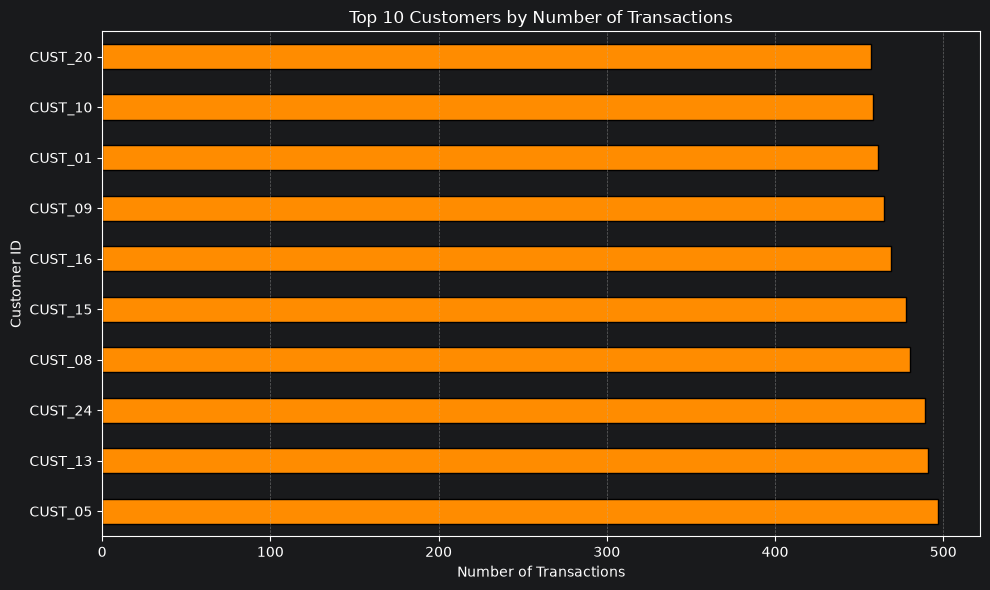

In [77]:
plt.figure(figsize=(10, 6))

top_10_customers_transactions.plot(
    kind="barh",
    color="darkorange",
    edgecolor="black"
)

plt.title("Top 10 Customers by Number of Transactions")
plt.xlabel("Number of Transactions")
plt.ylabel("Customer ID")

plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [78]:
average_transaction_value = cleaned_df["Total Spent"].mean()

print("Average Transaction Value:", average_transaction_value)

Average Transaction Value: 129.64253652525963


In [79]:
total_revenue = cleaned_df["Total Spent"].sum()

total_transactions = cleaned_df["Transaction ID"].nunique()

total_customers = cleaned_df["Customer ID"].nunique()

average_transaction = cleaned_df["Total Spent"].mean()

print("RETAIL SALES SUMMARY")
print("-------------------------")
print("Total Revenue:", total_revenue)
print("Total Transactions:", total_transactions)
print("Total Customers:", total_customers)
print("Average Transaction Value:", round(average_transaction, 2))

RETAIL SALES SUMMARY
-------------------------
Total Revenue: 1472998.5
Total Transactions: 11362
Total Customers: 25
Average Transaction Value: 129.64


In [85]:
location_summary = cleaned_df.groupby("Location").agg(
    Total_Revenue=("Total Spent", "sum"),
    Total_Transactions=("Transaction ID", "nunique"),
    Average_Sales=("Total Spent", "mean")
)

print("Sales Summary by Location:")
print(location_summary)

Sales Summary by Location:
          Total_Revenue  Total_Transactions  Average_Sales
Location                                                  
In-store       723567.5                5617     128.817429
Online         749431.0                5745     130.449260


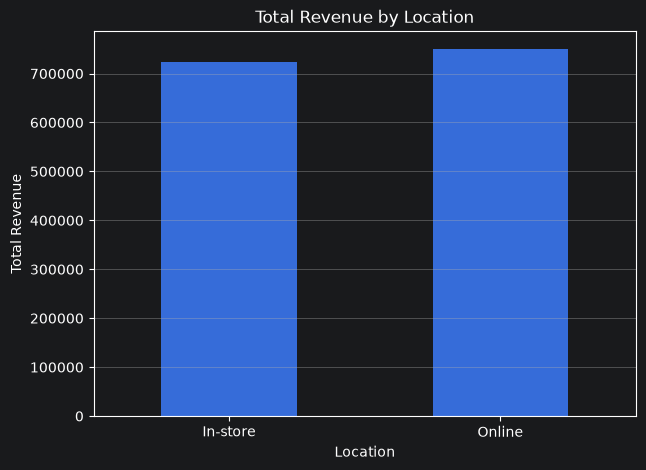

In [86]:
location_summary["Total_Revenue"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Total Revenue by Location"
)

plt.xlabel("Location")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

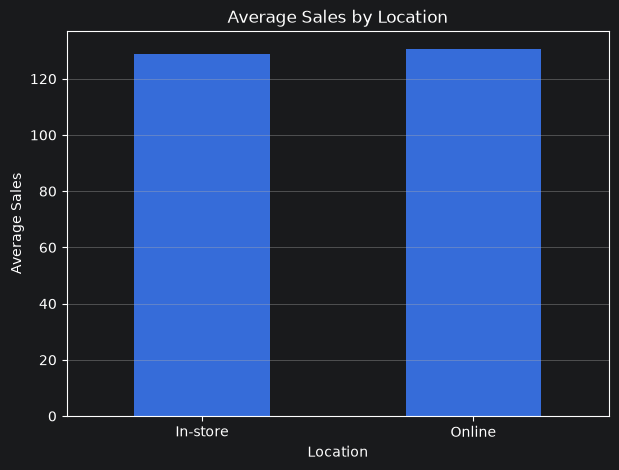

In [87]:
location_summary["Average_Sales"].plot(
    kind="bar",
    figsize=(7, 5),
    title="Average Sales by Location"
)

plt.xlabel("Location")
plt.ylabel("Average Sales")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

In [88]:
location_percentage = (
    location_summary["Total_Revenue"] /
    location_summary["Total_Revenue"].sum()
) * 100

print("Revenue Contribution by Location:")
print(location_percentage.round(2))

Revenue Contribution by Location:
Location
In-store    49.12
Online      50.88
Name: Total_Revenue, dtype: float64


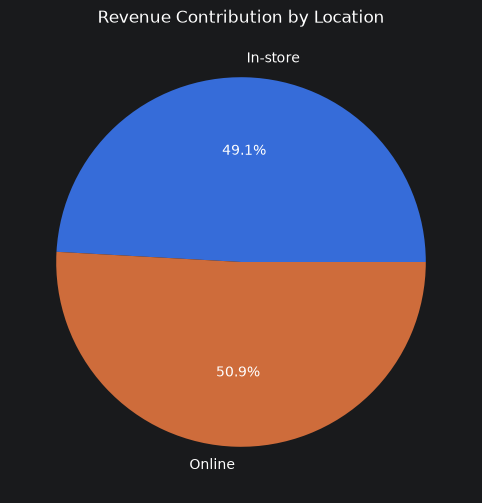

In [89]:
location_percentage.plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(6, 6),
    title="Revenue Contribution by Location"
)

plt.ylabel("")
plt.show()

In [90]:
best_location = location_summary["Total_Revenue"].idxmax()

print("Best Performing Location:", best_location)
print("Highest Revenue:", location_summary["Total_Revenue"].max())

Best Performing Location: Online
Highest Revenue: 749431.0


In [91]:
print("FINAL RETAIL SALES ANALYSIS")
print("----------------------------")

print("Total Revenue:", cleaned_df["Total Spent"].sum())
print("Total Transactions:", cleaned_df["Transaction ID"].nunique())
print("Total Customers:", cleaned_df["Customer ID"].nunique())

print("Best Performing Location:", location_summary["Total_Revenue"].idxmax())
print("Best Payment Method:", cleaned_df.groupby("Payment Method")["Total Spent"].sum().idxmax())
print("Best Sales Category:", cleaned_df.groupby("Category")["Total Spent"].sum().idxmax())
print("Highest Revenue Item:", cleaned_df.groupby("Item")["Total Spent"].sum().idxmax())

FINAL RETAIL SALES ANALYSIS
----------------------------
Total Revenue: 1472998.5
Total Transactions: 11362
Total Customers: 25
Best Performing Location: Online
Best Payment Method: Cash
Best Sales Category: Butchers
Highest Revenue Item: Item_25_FUR


In [92]:
cleaned_df.to_csv(
    "../Data/cleaned/final_retail_sales_data.csv",
    index=False
)

print("Final cleaned dataset saved successfully!")

Final cleaned dataset saved successfully!


In [102]:
final_summary.to_excel(
    "Retail_Sales_Summary.xlsx",
    index=False
)

print("Excel summary created successfully!")

Excel summary created successfully!


In [103]:
with pd.ExcelWriter(
    "Retail_Sales_Summary.xlsx",
    mode="a",
    engine="openpyxl"
) as writer:

    location_summary.to_excel(
        writer,
        sheet_name="Location Analysis"
    )

print("Location analysis added to Excel successfully!")

Location analysis added to Excel successfully!


In [104]:
category_summary = cleaned_df.groupby("Category").agg(
    Total_Revenue=("Total Spent", "sum"),
    Total_Transactions=("Transaction ID", "nunique"),
    Average_Sales=("Total Spent", "mean")
)

with pd.ExcelWriter(
    "Retail_Sales_Summary.xlsx",
    mode="a",
    engine="openpyxl"
) as writer:

    category_summary.to_excel(
        writer,
        sheet_name="Category Analysis"
    )

print("Category analysis added to Excel successfully!")

Category analysis added to Excel successfully!


In [7]:
payment_summary = cleaned_df.groupby("Payment Method").agg(
    Total_Revenue=("Total Spent", "sum"),
    Total_Transactions=("Transaction ID", "nunique"),
    Average_Sales=("Total Spent", "mean")
)

with pd.ExcelWriter(
    "Retail_Sales_Summary.xlsx",
    mode="a",
    engine="openpyxl"
) as writer:

    payment_summary.to_excel(
        writer,
        sheet_name="Payment Analysis"
    )

print("Payment analysis added to Excel successfully!")

Payment analysis added to Excel successfully!


In [8]:
monthly_summary = cleaned_df.groupby(
    cleaned_df["Transaction Date"].dt.to_period("M")
)["Total Spent"].sum()

monthly_summary.index = monthly_summary.index.astype(str)

monthly_summary = monthly_summary.reset_index()
monthly_summary.columns = ["Month", "Total Revenue"]

with pd.ExcelWriter(
    "Retail_Sales_Summary.xlsx",
    mode="a",
    engine="openpyxl"
) as writer:

    monthly_summary.to_excel(
        writer,
        sheet_name="Monthly Analysis",
        index=False
    )

print("Monthly analysis added to Excel successfully!")

Monthly analysis added to Excel successfully!


In [9]:
excel_file = pd.ExcelFile("Retail_Sales_Summary.xlsx")

print("Excel Workbook Sheets:")
print(excel_file.sheet_names)

Excel Workbook Sheets:
['Sheet1', 'Location Analysis', 'Category Analysis', 'Payment Analysis', 'Monthly Analysis']


In [10]:
from openpyxl import load_workbook

workbook = load_workbook("Retail_Sales_Summary.xlsx")

workbook["Sheet1"].title = "Main Summary"

workbook.save("Retail_Sales_Summary.xlsx")

print("Excel sheet renamed successfully!")

Excel sheet renamed successfully!


In [13]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import SimpleDocTemplate
from reportlab.platypus import Paragraph, Spacer
from reportlab.lib.styles import getSampleStyleSheet

print("PDF libraries imported successfully!")

PDF libraries imported successfully!


In [12]:
!python -m pip install reportlab

   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/2.0 MB ? eta -:--:--
   ----- -------------------------


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
pdf = SimpleDocTemplate(
    "Retail_Sales_Analysis_Report.pdf",
    pagesize=A4
)

styles = getSampleStyleSheet()

content = []

title = Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
)

content.append(title)
content.append(Spacer(1, 20))

pdf.build(content)

print("PDF report created successfully!")

PDF report created successfully!


In [15]:
from reportlab.platypus import PageBreak

content = []

content.append(Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
))

content.append(Spacer(1, 20))

content.append(Paragraph(
    "1. Project Overview",
    styles["Heading1"]
))

overview = """
This project focuses on analyzing retail store sales data
using Python. The main objective is to understand sales
performance, customer transactions, product categories,
payment methods, and monthly sales trends.

The analysis helps identify business patterns and provides
useful insights for better decision-making.
"""

content.append(Paragraph(overview, styles["BodyText"]))

content.append(Spacer(1, 15))

pdf.build(content)

print("Project overview added to PDF successfully!")

Project overview added to PDF successfully!


In [16]:
content = []

content.append(Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
))

content.append(Spacer(1, 20))

content.append(Paragraph(
    "1. Project Overview",
    styles["Heading1"]
))

overview = """
This project focuses on analyzing retail store sales data
using Python. The objective is to understand sales performance,
customer transactions, product categories, payment methods,
and monthly sales trends.
"""

content.append(Paragraph(overview, styles["BodyText"]))
content.append(Spacer(1, 15))

content.append(Paragraph(
    "2. Dataset Information",
    styles["Heading1"]
))

dataset_info = """
Original Dataset: retail_store_sales.csv<br/>
Original Records: 12,575<br/>
Cleaned Records: 11,362<br/>
Total Columns: 11<br/>
Missing Values After Cleaning: 0<br/>
Duplicate Rows: 0<br/>
"""

content.append(Paragraph(dataset_info, styles["BodyText"]))

pdf.build(content)

print("Dataset information added to PDF successfully!")

Dataset information added to PDF successfully!


In [17]:
content = []

content.append(Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
))

content.append(Spacer(1, 20))

content.append(Paragraph(
    "1. Project Overview",
    styles["Heading1"]
))

overview = """
This project analyzes retail store sales data using Python
to understand sales performance, customers, products,
payment methods, and sales trends.
"""

content.append(Paragraph(overview, styles["BodyText"]))
content.append(Spacer(1, 15))

content.append(Paragraph(
    "2. Dataset Information",
    styles["Heading1"]
))

dataset_info = """
Original Records: 12,575<br/>
Cleaned Records: 11,362<br/>
Total Columns: 11<br/>
Missing Values After Cleaning: 0<br/>
Duplicate Rows: 0
"""

content.append(Paragraph(dataset_info, styles["BodyText"]))
content.append(Spacer(1, 15))

content.append(Paragraph(
    "3. Data Cleaning Summary",
    styles["Heading1"]
))

cleaning_info = """
The dataset was cleaned using Python Pandas.

- Converted Transaction Date into datetime format.
- Replaced missing Item values with Unknown.
- Replaced missing Discount Applied values with Unknown.
- Removed rows with missing numerical values.
- Checked and confirmed that no duplicate rows remained.
- Saved the cleaned dataset as a CSV file.
"""

content.append(Paragraph(cleaning_info, styles["BodyText"]))

pdf.build(content)

print("Data cleaning summary added to PDF successfully!")

Data cleaning summary added to PDF successfully!


In [18]:
content = []

content.append(Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
))

content.append(Spacer(1, 20))

content.append(Paragraph(
    "1. Project Overview",
    styles["Heading1"]
))

content.append(Paragraph(
    "This project analyzes retail sales data using Python "
    "to understand business performance and sales trends.",
    styles["BodyText"]
))

content.append(Spacer(1, 15))

content.append(Paragraph(
    "2. Dataset Information",
    styles["Heading1"]
))

content.append(Paragraph(
    "Original Records: 12,575<br/>"
    "Cleaned Records: 11,362<br/>"
    "Total Columns: 11<br/>"
    "Missing Values After Cleaning: 0<br/>"
    "Duplicate Rows: 0",
    styles["BodyText"]
))

content.append(Spacer(1, 15))

content.append(Paragraph(
    "3. Data Cleaning Summary",
    styles["Heading1"]
))

content.append(Paragraph(
    "Converted dates, handled missing values, removed rows "
    "with missing numerical values, and checked duplicates.",
    styles["BodyText"]
))

content.append(Spacer(1, 15))

content.append(Paragraph(
    "4. Overall Sales Performance",
    styles["Heading1"]
))

sales_info = f"""
Total Revenue: {cleaned_df["Total Spent"].sum():,.2f}<br/>
Total Transactions: {cleaned_df["Transaction ID"].nunique():,}<br/>
Total Customers: {cleaned_df["Customer ID"].nunique():,}<br/>
Average Transaction Value: {cleaned_df["Total Spent"].mean():.2f}<br/>
Highest Transaction Value: {cleaned_df["Total Spent"].max():.2f}<br/>
Lowest Transaction Value: {cleaned_df["Total Spent"].min():.2f}
"""

content.append(Paragraph(sales_info, styles["BodyText"]))

pdf.build(content)

print("Sales performance added to PDF successfully!")

Sales performance added to PDF successfully!


In [19]:
category_revenue = cleaned_df.groupby("Category")["Total Spent"].sum().sort_values(ascending=False)

content = []

content.append(Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
))

content.append(Spacer(1, 20))

content.append(Paragraph(
    "5. Category Performance Analysis",
    styles["Heading1"]
))

for category, revenue in category_revenue.items():
    content.append(Paragraph(
        f"{category}: {revenue:,.2f}",
        styles["BodyText"]
    ))

content.append(Spacer(1, 15))

content.append(Paragraph(
    "Finding: Butchers generated the highest total revenue "
    "among all product categories.",
    styles["BodyText"]
))

pdf.build(content)

print("Category performance added to PDF successfully!")

Category performance added to PDF successfully!


In [20]:
payment_revenue = cleaned_df.groupby(
    "Payment Method"
)["Total Spent"].sum().sort_values(ascending=False)

print("Revenue by Payment Method:")
print(payment_revenue)

Revenue by Payment Method:
Payment Method
Cash              513676.0
Credit Card       481135.0
Digital Wallet    478187.5
Name: Total Spent, dtype: float64


In [21]:
location_revenue = cleaned_df.groupby(
    "Location"
)["Total Spent"].sum().sort_values(ascending=False)

print("Revenue by Location:")
print(location_revenue)

Revenue by Location:
Location
Online      749431.0
In-store    723567.5
Name: Total Spent, dtype: float64


In [24]:
top_items = cleaned_df.groupby("Item")["Quantity"].sum().sort_values(
    ascending=False
).head(10)

print("Top 10 Best-Selling Items:")
print(top_items)

Top 10 Best-Selling Items:
Item
Item_2_BEV      676.0
Item_16_MILK    627.0
Item_25_FUR     616.0
Item_19_MILK    589.0
Item_5_FUR      581.0
Item_13_FOOD    581.0
Item_1_MILK     578.0
Item_11_MILK    574.0
Item_11_FUR     573.0
Item_14_FOOD    566.0
Name: Quantity, dtype: float64


In [25]:
monthly_revenue = cleaned_df.groupby(
    cleaned_df["Transaction Date"].dt.month_name()
)["Total Spent"].sum()

print("Monthly Revenue Summary:")
print(monthly_revenue.sort_values(ascending=False))

print("\nHighest Revenue Month:", monthly_revenue.idxmax())
print("Lowest Revenue Month:", monthly_revenue.idxmin())

Monthly Revenue Summary:
Transaction Date
January      165611.0
July         124328.5
June         123969.0
December     123588.0
September    122256.0
May          119569.5
April        118933.5
August       116875.5
November     116256.5
March        115386.0
February     113153.5
October      113071.5
Name: Total Spent, dtype: float64

Highest Revenue Month: January
Lowest Revenue Month: October


In [26]:
yearly_revenue = cleaned_df.groupby(
    cleaned_df["Transaction Date"].dt.year
)["Total Spent"].sum()

print("Yearly Revenue:")
print(yearly_revenue)

Yearly Revenue:
Transaction Date
2022    484301.5
2023    465149.5
2024    499336.0
2025     24211.5
Name: Total Spent, dtype: float64


In [27]:
average_category_sales = cleaned_df.groupby(
    "Category"
)["Total Spent"].mean().sort_values(ascending=False)

print("Average Sales by Category:")
print(average_category_sales)

print("\nBest Category:", average_category_sales.idxmax())

Average Sales by Category:
Category
Butchers                              138.934553
Electric household essentials         133.918928
Beverages                             131.729853
Computers and electric accessories    129.493558
Food                                  129.484572
Furniture                             127.758219
Patisserie                            125.880570
Milk Products                         119.822807
Name: Total Spent, dtype: float64

Best Category: Butchers


In [28]:
print("FINAL BUSINESS INSIGHTS")
print("------------------------")

print("Highest Revenue Category:",
      cleaned_df.groupby("Category")["Total Spent"].sum().idxmax())

print("Highest Average Sales Category:",
      average_category_sales.idxmax())

print("Best Payment Method:",
      payment_revenue.idxmax())

print("Best Performing Location:",
      location_revenue.idxmax())

print("Best Selling Item:",
      top_items.idxmax())

print("Highest Revenue Month:",
      monthly_revenue.idxmax())

print("Highest Revenue Year:",
      yearly_revenue.idxmax())

FINAL BUSINESS INSIGHTS
------------------------
Highest Revenue Category: Butchers
Highest Average Sales Category: Butchers
Best Payment Method: Cash
Best Performing Location: Online
Best Selling Item: Item_2_BEV
Highest Revenue Month: January
Highest Revenue Year: 2024


In [29]:
content = []

# Project Title
content.append(Paragraph(
    "Retail Sales Data Analysis Report",
    styles["Title"]
))
content.append(Spacer(1, 20))

# 1. Project Overview
content.append(Paragraph("1. Project Overview", styles["Heading1"]))
content.append(Paragraph(
    "This project analyzes retail store sales data using Python "
    "to understand sales performance, customers, products, "
    "payment methods, and business trends.",
    styles["BodyText"]
))
content.append(Spacer(1, 15))

# 2. Dataset Information
content.append(Paragraph("2. Dataset Information", styles["Heading1"]))
content.append(Paragraph(
    "Original Records: 12,575<br/>"
    "Cleaned Records: 11,362<br/>"
    "Total Columns: 11<br/>"
    "Missing Values After Cleaning: 0<br/>"
    "Duplicate Rows: 0",
    styles["BodyText"]
))
content.append(Spacer(1, 15))

# 3. Data Cleaning
content.append(Paragraph("3. Data Cleaning Summary", styles["Heading1"]))
content.append(Paragraph(
    "Converted transaction dates, handled missing values, "
    "removed rows with missing numerical values, and checked "
    "duplicate records.",
    styles["BodyText"]
))
content.append(Spacer(1, 15))

# 4. Overall Sales Performance
content.append(Paragraph("4. Overall Sales Performance", styles["Heading1"]))
content.append(Paragraph(
    f"Total Revenue: {cleaned_df['Total Spent'].sum():,.2f}<br/>"
    f"Total Transactions: {cleaned_df['Transaction ID'].nunique():,}<br/>"
    f"Total Customers: {cleaned_df['Customer ID'].nunique():,}<br/>"
    f"Average Transaction Value: {cleaned_df['Total Spent'].mean():.2f}",
    styles["BodyText"]
))
content.append(Spacer(1, 15))

# 5. Category Analysis
content.append(Paragraph("5. Category Performance", styles["Heading1"]))
for category, revenue in category_revenue.items():
    content.append(Paragraph(
        f"{category}: {revenue:,.2f}",
        styles["BodyText"]
    ))
content.append(Spacer(1, 15))

# 6. Payment Analysis
content.append(Paragraph("6. Payment Method Analysis", styles["Heading1"]))
for method, revenue in payment_revenue.items():
    content.append(Paragraph(
        f"{method}: {revenue:,.2f}",
        styles["BodyText"]
    ))
content.append(Spacer(1, 15))

# 7. Location Analysis
content.append(Paragraph("7. Location Analysis", styles["Heading1"]))
for location, revenue in location_revenue.items():
    content.append(Paragraph(
        f"{location}: {revenue:,.2f}",
        styles["BodyText"]
    ))
content.append(Spacer(1, 15))

# 8. Top 10 Best-Selling Items
content.append(Paragraph("8. Top 10 Best-Selling Items", styles["Heading1"]))
for item, quantity in top_items.items():
    content.append(Paragraph(
        f"{item}: {quantity:.0f} units",
        styles["BodyText"]
    ))
content.append(Spacer(1, 15))

# 9. Monthly Analysis
content.append(Paragraph("9. Monthly Revenue Analysis", styles["Heading1"]))
content.append(Paragraph(
    f"Highest Revenue Month: {monthly_revenue.idxmax()}<br/>"
    f"Lowest Revenue Month: {monthly_revenue.idxmin()}",
    styles["BodyText"]
))
content.append(Spacer(1, 15))

# 10. Yearly Analysis
content.append(Paragraph("10. Yearly Revenue Analysis", styles["Heading1"]))
for year, revenue in yearly_revenue.items():
    content.append(Paragraph(
        f"{year}: {revenue:,.2f}",
        styles["BodyText"]
    ))
content.append(Spacer(1, 15))

# 11. Final Business Insights
content.append(Paragraph("11. Final Business Insights", styles["Heading1"]))
content.append(Paragraph(
    "Best Revenue Category: Butchers<br/>"
    "Best Payment Method: Cash<br/>"
    "Best Performing Location: Online<br/>"
    "Best Selling Item: Item_2_BEV<br/>"
    "Highest Revenue Month: January<br/>"
    "Highest Revenue Year: 2024",
    styles["BodyText"]
))

pdf.build(content)

print("Complete PDF report created successfully!")

Complete PDF report created successfully!


In [30]:
from pathlib import Path

pdf_path = Path("Retail_Sales_Analysis_Report.pdf")

if pdf_path.exists():
    print("PDF file exists!")
    print("File size:", round(pdf_path.stat().st_size / 1024, 2), "KB")
else:
    print("PDF file not found.")

PDF file exists!
File size: 3.55 KB
